## Final fitting of HPK Wlen data

First we do the sequential fitting process to show how it works

then both the global paramaterized and free fits

------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']


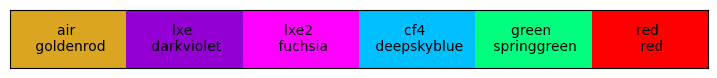

In [46]:
import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from scipy import optimize as opt
from scipy.stats import norm
from scipy.stats import triang
import time
import json

import numpy as np
import iminuit
from iminuit import Minuit
from scipy.ndimage import gaussian_filter1d

from PDEModel import OpticsDataLoader as ODL
import PDEModel.MathEquations as ME
import PDEModel.PhotonInfo as PI
# from PDEModel.PNJunction import *
import PDEModel.PNJunction as PNJ

import FittingTools.PDE_fittingTools as SS
from FittingTools import FittingFunctions as FF

from scipy.interpolate import interp1d

import PDEModel.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

---
---
## Parameters shared by everything

rel vals: [ 1.          2.00107747  3.03916961  4.22796768  5.73602081  7.36821475
  9.4554152  12.02284971 15.97622144 21.10245216]
0.03755108980794766


array([0.10050373, 0.10777755, 0.13483694, 0.18935681, 0.27041635,
       0.37536116, 0.50249478, 0.65091935, 0.82015913])

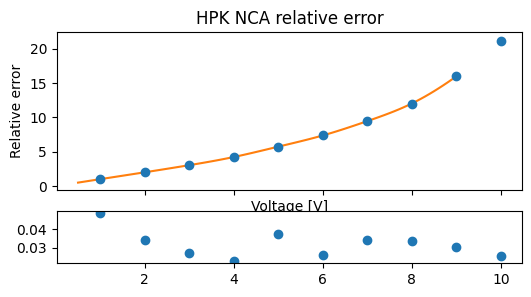

In [47]:
## loading in Harry's NCA error data 
file_path_nca = os.path.join(VERA_DATA_PATH, "NCA_errors/HPK_Q_new.csv")

xV_nca, yV_nca, yE_nca = np.loadtxt(file_path_nca, delimiter=",", unpack=True, skiprows=1, usecols=(0, 1, 2))

yV_nca_relative = yV_nca/min(yV_nca)
yE_nca_relative = yE_nca/yV_nca
print("rel vals:", yV_nca_relative)
finterp_nca = interp1d(xV_nca, yV_nca_relative, kind = "cubic", fill_value = "extrapolate")
finterp_ncaError = interp1d(xV_nca, yE_nca_relative, kind = "cubic", fill_value = "extrapolate")

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=1, figsize = (6, 3), height_ratios=[3, 1])
ax1.errorbar(xV_nca, yV_nca_relative, yerr=10*yE_nca_relative, marker = "o", linestyle = "", label = "NCA errors")
xfurther = np.arange(0.5, 9, 0.1)
ax1.plot(xfurther, finterp_nca(xfurther), label = "Interpolated")

ax2.plot(xV_nca, yE_nca_relative, marker = "o", linestyle = "", label = "NCA errors")
ax1.set_xlabel("Voltage [V]")
ax1.set_ylabel("Relative error")
ax1.set_title("HPK NCA relative error")
# ax2.plot(xfurther, finterp_ncaError(xfurther), label = "Interpolated")

def getClosestNCAError(voltage):
    amin = np.argmin(np.abs(xV_nca - voltage))
    return yE_nca_relative[amin]

print(getClosestNCAError(4.6))

def quadErrors(value, valueErrors, *constantRelErrors):
    creArray = np.array(constantRelErrors)
    return value * np.sqrt((valueErrors/value)**2 + np.sum((creArray)**2))

xt = np.arange(0.1, 1, 0.1)
yt = xt**2
yerr = 0.1 * yt

quadErrors(yt, yerr/yt, 1.0, 0.1)


In [48]:
MCFWHM = 4.5 # nm/mm

dhFranta = ODL.OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
dhFranta_warm = ODL.OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-293K.txt"))
dhDefault = ODL.OpticsData()

## VERA SYSTEMATICS
class systematics:
    def __init__(self):
        return

sys1 = systematics()

sys1.mScale = 1.32
sys1.mc_fwhm = MCFWHM * sys1.mScale # in nm
sys1.diodeError = 0.03
sys1.FF1 = 0.6
sys1.vOffset = 0.5

sys1.dh = None
# sys1.dh = dhFranta_warm
sys1.temp = 160
peSat = 1.0

peOutFileName = "HPK_Pcurves_franta_global_nested_temp.csv"

sys1.tOxide = 19.51 # nm default optics data value
# 17.2 #default value, - is 15.89, + is 19.63

# 19.51 # franta data value
# - is 16.67, + is 21.36

fitFlag = "" # "floatPsat" or 
UVLim = 380

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-150K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-293K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt


In [49]:
# # plotting the input n, k datasets
# wlens = np.arange(150, 1000, 5)

# fig, (axn, axk, axA) = plt.subplots(3, 1, figsize = (6, 6), sharex = True)

# axn.plot(wlens, dhFranta.SiIndex(wlens).real, label = "franta")
# axn.plot(wlens, dhDefault.SiIndex(wlens).real, label = "default")

# axn.legend()

# axk.semilogy(wlens, dhFranta.SiIndex(wlens).imag, label = "franta")
# axk.semilogy(wlens, dhFranta_warm.SiIndex(wlens).imag, label = "franta - RT")
# axk.semilogy(wlens, dhDefault.SiIndex(wlens).imag, label = "default")

# axA.semilogy(wlens, )

# axk.legend()


In [50]:
# piTest = PI.PhotonInfo(wlen=np.array([400]), theta_1=0, dataHelper= sys1.dh, materialTemp=150)

# pnTest = PNJ.PNJunction(tOxide = sys1.tOxide, dp_star = 0.01, Xpn = 2150, dw_star = 5500)
# pnTest.calcW_both(piTest)

In [51]:
# with open("input_systematics.json", 'r') as file:
#     json_systematic = json.load(file)

# sys1.FF1 = json_systematic["HPK_VUV4"]["input_systematics"]["FF"]
# tOxide_values = json_systematic["HPK_VUV4"]["input_systematics"]["tOxide"]

fixedPars_Boring = {"FF": sys1.FF1, "smoothSigma": sys1.mc_fwhm,
                    "Temperature":sys1.temp, "dh":sys1.dh,
                    "quantum": True,  "window":True}

fixedPars_physics = {"tOxide":sys1.tOxide, "case":"B"}
fixedPars_parametrized = {"Ae":peSat, "Ah":1.0}

fixedPars_all = {**fixedPars_Boring, **fixedPars_physics}

allBoundsDict = {"dp_star":(0.01, 15), "Xpn": (0.2e3, 4.5e3), "dw_star": (4.5e3, 15e3)}

print(fixedPars_Boring)
print(fixedPars_physics)
print(fixedPars_parametrized)


if (fixedPars_Boring["dh"] is not None) and fixedPars_Boring["Temperature"] is not None:
    if "franta" in fixedPars_Boring["dh"].mPathSi or "Franta" in fixedPars_Boring["dh"].mPathSi:
        print("Using franta and setting temperature. this is wrong. EXITING")
        sys.exit()

{'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True}
{'tOxide': 19.51, 'case': 'B'}
{'Ae': 1.0, 'Ah': 1.0}


In [52]:
print(fixedPars_Boring)
print(fixedPars_physics)
print(fixedPars_parametrized)


if (fixedPars_Boring["dh"] is not None) and fixedPars_Boring["Temperature"] is not None:
    if "franta" in fixedPars_Boring["dh"].mPathSi or "Franta" in fixedPars_Boring["dh"].mPathSi:
        print("Using franta and setting temperature. this is wrong. EXITING")
        sys.exit()

{'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True}
{'tOxide': 19.51, 'case': 'B'}
{'Ae': 1.0, 'Ah': 1.0}


---
### Loading Data

In [53]:
file_path = os.path.join(VERA_DATA_PATH, "HPK_PDE_sept24.csv")
# file_path = os.path.join(VERA_DATA_PATH, "HPK_IR_PDE-Feb12_2024-Harry.csv")
# file_path = os.path.join(VERA_DATA_PATH, "HPK_IR_PDE_feb24_stat_error_only.csv")

df = pd.read_csv(file_path, header=0)

if 'Harry' in file_path:
    print("Harry's data, cleaning up")
    # filter for angle = 0
    df = df[(df['Angle'] == 0)]
    df = df[(df['Wavelength'] > 300) & (df['Overvoltage'] > 0.5)]
# print(df.columns)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())
# print(df['Wavelength'].unique())

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

# print("Angles:", data_angles)
# print("voltages:", data_voltages)

# take out one wavelength
# df = df[(df['Wavelength'] != 399.975) & ((df['Wavelength'] < 695) | (df['Wavelength'] > 705))]

     Wavelength  Angle  Overvoltage          Resp       PDE  PDE_error
387     789.983      0            8  1.487610e-13  0.114928   0.004171
388     799.950      0            8  1.338970e-13  0.103445   0.004119
389     810.007      0            8  1.252880e-13  0.096794   0.003343
390     820.008      0            8  1.147380e-13  0.088643   0.003168
391     829.983      0            8  1.056960e-13  0.081658   0.002833
--------------------------
Overvoltage
1    49
2    49
3    49
4    49
5    49
6    49
7    49
8    49
Name: count, dtype: int64
Angle
0    392
Name: count, dtype: int64


Vc = 1.515 ± 0.074
---- Harry Pe values ----
{1: 0.486306, 2: 0.733673, 3: 0.858569, 4: 0.925484, 5: 0.961845, 6: 0.981696, 7: 0.993065, 8: 0.997103, 9: 1.0}


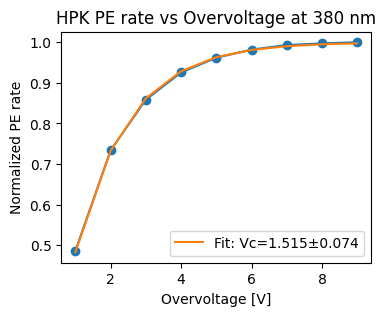

In [54]:
 ## Loading in Harry's PE data
file_path_pe = os.path.join(VERA_DATA_PATH, "HPK_EHPAIR_183K.csv")
df_pe = pd.read_csv(file_path_pe, header=0)

# print(df_pe)
df_pe=df_pe[df_pe['Wavelength'] == 380]
# print(df_pe)

harryPe = df_pe['normalized rate'].values
harryVoltagePE = df_pe['Overvoltage'].values
# harryVPE_err_183 = df_pe['']
harryVPE_err_183 = 0.03 * np.ones_like(harryPe)

harryPedict = {df_pe["Overvoltage"].values[i]: harryPe[i] for i in range(len(harryPe))}

chisq = lambda Vc: np.sum(((ME.Pcar_parametrized(harryVoltagePE, Vc, 1.0) - harryPe) / harryVPE_err_183)**2)
m = Minuit(chisq, Vc=1.9); m.migrad()
print(f"Vc = {m.values['Vc']:.3f} ± {m.errors['Vc']:.3f}")

print("---- Harry Pe values ----")
print(harryPedict)

plt.figure(figsize=(4, 3))
plt.plot(harryVoltagePE, harryPe, marker = "o")
plt.plot(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, m.values['Vc'], 1.0), label = f"Fit: Vc={m.values['Vc']:.3f}±{m.errors['Vc']:.3f}")
plt.xlabel("Overvoltage [V]")
plt.ylabel("Normalized PE rate")
plt.title("HPK PE rate vs Overvoltage at 380 nm")
plt.legend()
plt.show()


data Angles: [0]
Data voltages: [1 2 3 4 5 6 7 8]
temperature scaling not tested/validated below 300nm, be careful
temperature scaling not tested/validated below 300nm, be careful


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


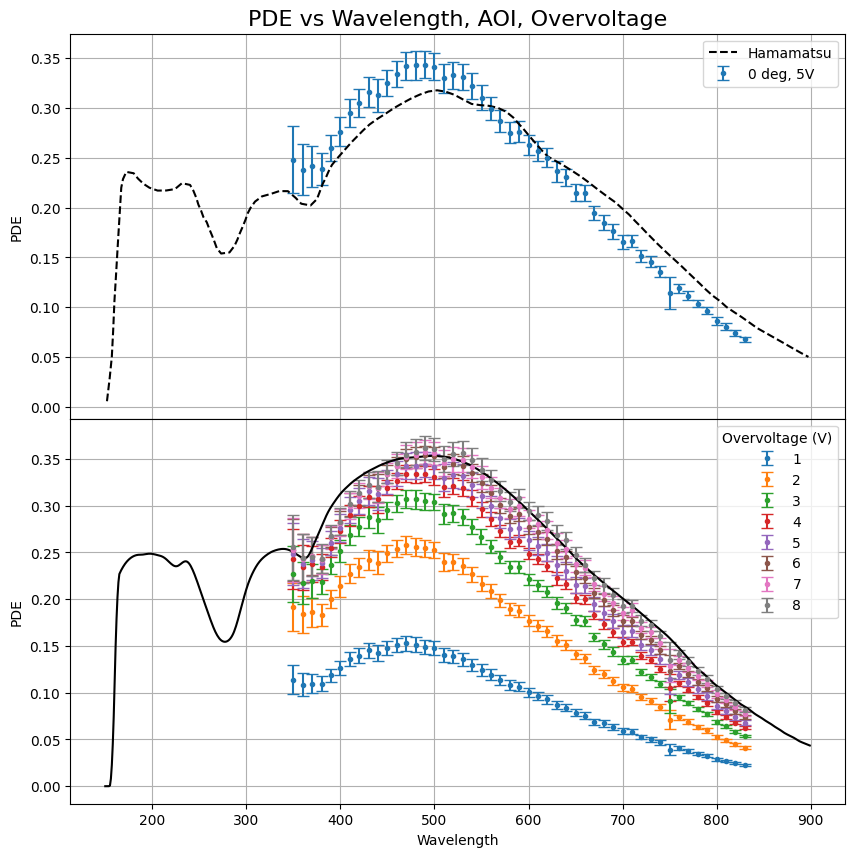

In [55]:
## Plot the data
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize = (10, 10))
print("data Angles:", data_angles)
print("Data voltages:", data_voltages)

for angle in data_angles:
    dt1 = df[(df['Angle'] == angle) & (df['Overvoltage'] == 5)]

    dt1.plot(x='Wavelength', y = "PDE", yerr="PDE_error", capsize=4, label = f"{angle:0.0f} deg, 5V", linestyle = "", marker = ".", ax = ax1)
    
ax1.legend(title = "AOI (deg)")
ax1.set_ylabel("PDE")

for voltage in data_voltages:
    dt2 = df[(df['Angle'] == 0) & (df['Overvoltage'] == voltage)]
    dt2.plot(x='Wavelength', y = "PDE",yerr = "PDE_error", capsize=4, label = f"{voltage:0.0f}", linestyle = "", marker = ".", ax = ax2)

ax2.legend(title = "Overvoltage (V)")
ax2.set_ylabel("PDE")

# plotting some example curves
xExampleWlen = np.arange(150, 900, 1)
yExamplePDE = FF.PDE_allArgs_wlen(xExampleWlen, 0,
                             dp_star = 1.4, Xpn = 2400, 
                             dw_star = 14.5e3, pe=0.99, ph=0.35,
                             **fixedPars_Boring, **fixedPars_physics)
ax2.plot(xExampleWlen, yExamplePDE, label = "Example Fit", color = "black", linestyle = "-")

# hamamatsu curves
hamX, hamY = ODL.Load_Ham_data()
ax1.plot(hamX, hamY, label = "Hamamatsu", color = "black", linestyle = "--")

ax1.grid(), ax2.grid()
ax1.set_title("PDE vs Wavelength, AOI, Overvoltage", fontsize = 16)
ax1.legend()
plt.subplots_adjust(hspace=0)
plt.show()

---
### UV high V Fitting
No nested/nuisance pars are required here  
Global float: 
* float $dp^*$, use non parametrized Pe

In [56]:
 ##-- Buiding A1 dataset --##
# dataset 0A
v_0A = data_voltages[-1]
angle_0A = data_angles[0]

# temporary datasets. can include second high voltage if desired
dfA_t1 = df[(df['Overvoltage'] == data_voltages[-1]) & (df['Wavelength'] < UVLim)]

fullError = quadErrors(dfA_t1['PDE'].values, dfA_t1['PDE_error'].values, sys1.diodeError, getClosestNCAError(v_0A))
data_UV_V = [
    {"wlen":np.array(dfA_t1['Wavelength'].values), "yVals": dfA_t1['PDE'], 
     "yErrs": fullError, "theta1": angle_0A}]

print("voltage wanted:", v_0A, "V")
print("angle wanted:", angle_0A, "deg")
# print("data_UV_V[0]:", data_UV_V[0])


voltage wanted: 8 V
angle wanted: 0 deg


In [57]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen))

fixedPars_A_UV = {**fixedPars_all, "Xpn": 2e3, "dw_star":10e3, "ph":0.0, "pe":peSat}

floatPars_A_UV = {"dp_star": 1.5}
floatBounds_A_UV = {"dp_star": (0.01, 14)}

if fitFlag == "floatPsat":
    fixedPars_A_UV.pop("pe")
    floatPars_A_UV["pe"] = peSat
    floatBounds_A_UV["pe"] = (0.0, 1.1)
    
elif fitFlag == "floatFF":
    fixedPars_A_UV.pop("FF")
    floatPars_A_UV["FF"] = sys1.FF1
    floatBounds_A_UV["FF"] = (0.0, 1.1)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']


In [58]:
print("------ Case AE-UV setup ------")
SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen, dataObj=data_UV_V, dFixed=fixedPars_A_UV, dFloat=floatPars_A_UV,
                                   dBounds=floatBounds_A_UV, yNames=("yVals", "yErrs"), verbose=False)
xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_A_UV, functionToFit=FF.PDE_allArgs_wlen)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_A_UV, functionToFit=FF.PDE_allArgs_wlen)

print("------ Case AE-UV Fit ------")
result_A_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_A_UV, data_UV_V, FF.PDE_allArgs_wlen), method='migrad')
SS.GenericResiduals(x0=result_A_UV.x, dataObj=data_UV_V, functionToFit=FF.PDE_allArgs_wlen, fixedArgs_dict=fixedPars_A_UV, verbose=False, yNames=("yVals", "yErrs"))
# print(result_A_UV)
print("chi2 score-ish:", result_A_UV.fun)

resDict_A_UV = SS.GetResDict(result_A_UV, xoAE_UV_Names)
resDictErrors_A_UV = SS.GetResErrorDict(result_A_UV, xoAE_UV_Names)
print(resDict_A_UV)
print("errors:", resDictErrors_A_UV)

------ Case AE-UV setup ------
------ Case AE-UV Fit ------
chi2 score-ish: 3.3579022165320938
{'dp_star': 2.144}
errors: {'dp_star': 0.6539}


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/iminuit/minuit.py:791: ComplexWarning: Casting complex values to real discards the imaginary part
  fm = migrad(ncall, self._tolerance)


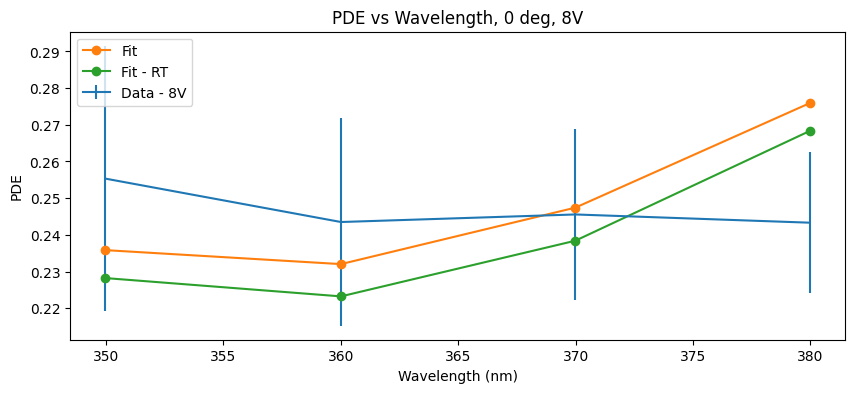

In [59]:
figure = plt.figure(figsize=(10, 4))

yTest=FF.PDE_allArgs_wlen(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **floatPars_A_UV, **fixedPars_A_UV)

# data
plt.errorbar(data_UV_V[0]["wlen"], data_UV_V[0]["yVals"], yerr=data_UV_V[0]["yErrs"], label="Data - 8V")

# fit
yFit = FF.PDE_allArgs_wlen(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_A_UV, **fixedPars_A_UV)
plt.plot(data_UV_V[0]["wlen"], yFit, label="Fit", marker="o")

# fit no smearing
toPlotModified = fixedPars_A_UV.copy()
toPlotModified['Temperature'] = 300
yTest_rt=FF.PDE_allArgs_wlen(wlen=data_UV_V[0]["wlen"], theta1=data_UV_V[0]["theta1"], **resDict_A_UV, **toPlotModified)
plt.plot(data_UV_V[0]["wlen"], yTest_rt, label="Fit - RT", marker="o")

plt.xlabel("Wavelength (nm)")
plt.ylabel("PDE")
plt.title("PDE vs Wavelength, 0 deg, 8V")
plt.legend()
plt.show()

In [60]:
# ## some kind of measured quantum yield
# yPDE_data = data_UV_V[0]["yVals"]
# xPDE = data_UV_V[0]["wlen"]
# yTransmission = PhotonInfo(wlen = xPDE).T_total_windowAndOxide(20)

# yData_internal = yPDE_data / yTransmission / FF1
# xAbsorption = PhotonInfo(wlen = xPDE).muSi

# plt.plot(1/xAbsorption, yData_internal, marker = "o")

---
---
### UV all V Fitting
No nested/nuisance pars are required here  
Global float: 
* float $dp^*$
* parametrized Pe

In [61]:
##-- Buiding A1 dataset --##
v_0A = data_voltages[-1]
angle_0A = data_angles[0]
data_UV1 = []

# temporary datasets. can include second high voltage if desired
for volt in data_voltages[:]:
    dfA_uv_all = df[(df['Overvoltage'] == volt) & (df['Wavelength'] < UVLim)]
    
    fullError = quadErrors(dfA_uv_all['PDE'].values, dfA_uv_all['PDE_error'].values, sys1.diodeError, getClosestNCAError(volt))

    oneD_dict = {"wlen":dfA_uv_all['Wavelength'].values, "yVals": dfA_uv_all['PDE'], "yErrs": fullError, "theta1": angle_0A, "voltage": volt-0.1}
    data_UV1.append(oneD_dict)

print("voltage wanted:", v_0A, "V")
print("angle wanted:", angle_0A, "deg")

# SS.CheckDataSetKey_consistent(data_UV_all, True);

voltage wanted: 8 V
angle wanted: 0 deg


In [62]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen_parametrized))

fixedPars_UV = {**fixedPars_Boring, **fixedPars_physics, "Xpn": 2.0e3, "dw_star":10e3, "Vh":1000, "Ah":0.0, "Ae":peSat}

floatPars_UV = {"dp_star": 1.5, "Ve":1.8}
floatBounds_UV = {"dp_star": (0.01, 10), "Ve": (0, 4)}
# SS.AddNonesToDict(dAddTo=floatBounds_UV, dRef=floatPars_UV)

if fitFlag == "floatPsat":
    fixedPars_UV.pop("Ae")
    floatPars_UV["Ae"] = peSat
    floatBounds_UV["Ae"] = (0.0, 1.1)
elif fitFlag == "floatFF":
    fixedPars_UV.pop("FF")
    floatPars_UV["FF"] = FF1
    floatBounds_UV["FF"] = (0.0, 1.1)

print("------ Case UV-all setup ------")
SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized, dataObj=data_UV1, dFixed=fixedPars_UV, dFloat=floatPars_UV,
                                   dBounds=floatBounds_UV, yNames=("yVals", "yErrs"), verbose=False)
xoAE_UV, xoAE_UV_Names = SS.BuildX0(floatDict=floatPars_UV, functionToFit=FF.PDE_allArgs_wlen_parametrized)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_UV, functionToFit=FF.PDE_allArgs_wlen_parametrized)

print("------ Case UV-all Fit ------")
result_UV = iminuit.minimize(SS.GenericResiduals, x0=xoAE_UV, bounds = xABounds, args=(fixedPars_UV, data_UV1, FF.PDE_allArgs_wlen_parametrized), method='migrad')
SS.GenericResiduals(x0=result_UV.x, dataObj=data_UV1, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_UV, verbose=False, yNames=("yVals", "yErrs"))
# print(result_UV)
print("chi2 score-ish:", result_UV.fun)

resDict_UV = SS.GetResDict(result_UV, xoAE_UV_Names)
resDictErrors_UV = SS.GetResErrorDict(result_UV, xoAE_UV_Names)
print(resDict_UV)
print("errors:", resDictErrors_UV)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'voltage', 'Ve', 'Vh', 'Ae', 'Ah', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
------ Case UV-all setup ------
------ Case UV-all Fit ------
chi2 score-ish: 9.545720206795709
{'dp_star': 1.1297, 'Ve': 1.6813}
errors: {'dp_star': 0.3121, 'Ve': 0.0909}
chi2 score-ish: 9.545720206795709
{'dp_star': 1.1297, 'Ve': 1.6813}
errors: {'dp_star': 0.3121, 'Ve': 0.0909}


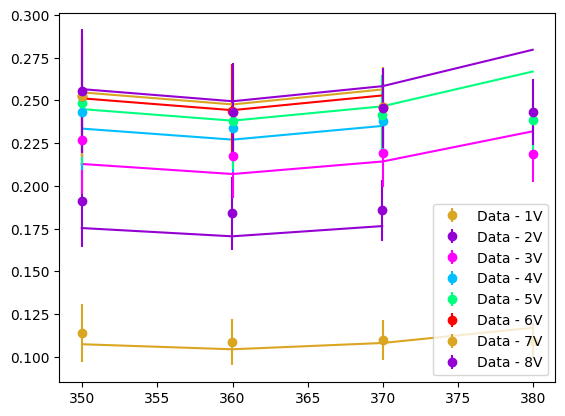

In [63]:
## plotting ##
ms.ResetColorCycle()
for oneD in data_UV1:
    col = ms.GetNextColor()
    plt.errorbar(oneD["wlen"], oneD["yVals"], yerr=oneD["yErrs"], label=f"Data - {oneD['voltage']:0.0f}V", marker = "o", linestyle = "None", color = col)

    # fit
    yFit = FF.PDE_allArgs_wlen_parametrized(wlen=oneD["wlen"], theta1=oneD["theta1"], voltage = oneD["voltage"], **resDict_UV, **fixedPars_UV)
    plt.plot(oneD["wlen"], yFit,color = col)

plt.legend()
plt.show()

---
### Sequential fitting - all wavelengths

Now including all wavelengths, keeping values from front of junction

In [64]:
data_ir1 = []
for V in data_voltages[:]:
    dfA_t1 = df[(df['Overvoltage'] == V)]
    fullError = quadErrors(dfA_t1['PDE'].values, dfA_t1['PDE_error'].values, sys1.diodeError, getClosestNCAError(V))
    oneD_dict = {"wlen":dfA_t1['Wavelength'].values,
                 "yVals": dfA_t1['PDE'], "yErrs": fullError,
                 "theta1": angle_0A, "voltage": V}

    # print(dfA_t1['PDE'].values[0:10])
    data_ir1.append(oneD_dict)

In [65]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen_parametrized))

fixedPars_ir = {**fixedPars_Boring, **fixedPars_physics}
fixedPars_ir = {**fixedPars_ir, **resDict_UV, "Ah": 1, "Ae":peSat} # this isn't a typo

floatPars_ir = {"Xpn": 2.0e3, "dw_star":8e3, "Vh":17}
floatBounds_ir = {"Xpn": (0.0, 4e3), "dw_star": (4e3, 20e3), "Vh": (0, 30)}
print(fixedPars_ir)
print(floatPars_ir)
# SS.AddNonesToDict(dAddTo=floatBounds_ir, dRef=floatPars_ir)

if fitFlag == "floatPsat":
    fixedPars_ir.pop("Ae")
    floatPars_ir["Ae"] = peSat
    floatBounds_ir["Ae"] = (0.0, 1.1)

print("------ Case IR-all setup ------")
SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized, dataObj=data_ir1, dFixed=fixedPars_ir, dFloat=floatPars_ir,
                                   dBounds=floatBounds_ir, yNames=("yVals", "yErrs"), verbose=False)
xoAE_ir, xoAE_ir_Names = SS.BuildX0(floatDict=floatPars_ir, functionToFit=FF.PDE_allArgs_wlen_parametrized)
xABounds = SS.BuildX0_bounds(floatBoundsDict=floatBounds_ir, functionToFit=FF.PDE_allArgs_wlen_parametrized)

print("------ Case IR-all Fit ------")
result_ir = iminuit.minimize(SS.GenericResiduals, x0=xoAE_ir, bounds = xABounds, args=(fixedPars_ir, data_ir1, FF.PDE_allArgs_wlen_parametrized), method='migrad')
SS.GenericResiduals(x0=result_ir.x, dataObj=data_ir1, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_ir, verbose=False, yNames=("yVals", "yErrs"))
# print(result_ir)
print("chi2 score-ish:", result_ir.fun)

resDict_ir = SS.GetResDict(result_ir, xoAE_ir_Names)
resDictErrors_ir = SS.GetResErrorDict(result_ir, xoAE_ir_Names)
print(resDict_ir)
print("errors:", resDictErrors_ir)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'voltage', 'Ve', 'Vh', 'Ae', 'Ah', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
{'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True, 'tOxide': 19.51, 'case': 'B', 'dp_star': 1.1297, 'Ve': 1.6813, 'Ah': 1, 'Ae': 1.0}
{'Xpn': 2000.0, 'dw_star': 8000.0, 'Vh': 17}
------ Case IR-all setup ------
------ Case IR-all Fit ------
chi2 score-ish: 219.63925860706203
{'Xpn': 2038.4343, 'dw_star': 11899.1739, 'Vh': 13.3651}
errors: {'Xpn': 45.2376, 'dw_star': 525.5613, 'Vh': 0.7554}
chi2 score-ish: 219.63925860706203
{'Xpn': 2038.4343, 'dw_star': 11899.1739, 'Vh': 13.3651}
errors: {'Xpn': 45.2376, 'dw_star': 525.5613, 'Vh': 0.7554}


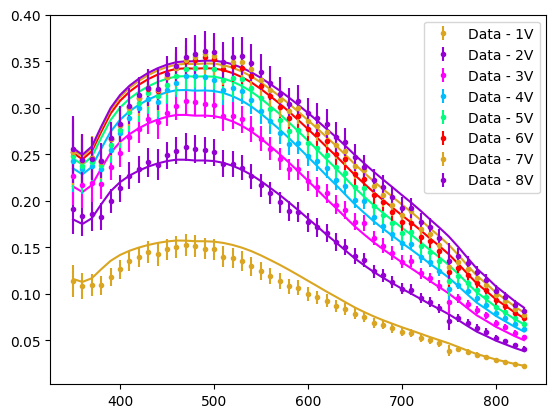

In [66]:
## plotting ##
ms.ResetColorCycle()
for oneD in data_ir1:
    col = ms.GetNextColor()
    plt.errorbar(oneD["wlen"], oneD["yVals"], yerr=oneD["yErrs"], label=f"Data - {oneD['voltage']:0.0f}V", 
                 marker = "o", markersize = 3, linestyle = "None", color = col)

    # fit
    yFit = FF.PDE_allArgs_wlen_parametrized(wlen=oneD["wlen"], theta1=oneD["theta1"], voltage = oneD["voltage"], **resDict_ir, **fixedPars_ir)
    plt.plot(oneD["wlen"], yFit,color = col)

# plt.xlim(340, 450)
plt.legend()
plt.show()

In [67]:
# Printing results and errors for the three sequential fits along with chi2 scores
print("UV limit:", UVLim)
print("UV high V Fit:")
print("Results:", resDict_A_UV)
print("Errors:", resDictErrors_A_UV)
print("Chi2:", result_A_UV.fun)

print("\nUV all V Fit:")
print("Results:", resDict_UV)
print("Errors:", resDictErrors_UV)
print("Chi2:", result_UV.fun)

print("\nIR Fit:")
print("Results:", resDict_ir)
print("Errors:", resDictErrors_ir)
print("Chi2:", result_ir.fun)

UV limit: 380
UV high V Fit:
Results: {'dp_star': 2.144}
Errors: {'dp_star': 0.6539}
Chi2: 3.3579022165320938

UV all V Fit:
Results: {'dp_star': 1.1297, 'Ve': 1.6813}
Errors: {'dp_star': 0.3121, 'Ve': 0.0909}
Chi2: 9.545720206795709

IR Fit:
Results: {'Xpn': 2038.4343, 'dw_star': 11899.1739, 'Vh': 13.3651}
Errors: {'Xpn': 45.2376, 'dw_star': 525.5613, 'Vh': 0.7554}
Chi2: 219.63925860706203


---
## Global fit, parametrized Pe, Ph
* float global: $X_{pn}$, $dw^*$, $dp^*$, $V_e$, $V_h$, $Ae$
* no nested fitting, not floating individually: $P_e$, $P_h$

data is an array of dicts, each dict is a dataset. Not using array of OneNuisanceDataSet

In [68]:
Ndata = 0
##-- Buiding Vis all dataset --##
data_global1 = []
for V in data_voltages[:]:
    dfA_t1 = df[(df['Overvoltage'] == V)]
    fullError = quadErrors(dfA_t1['PDE'].values, dfA_t1['PDE_error'].values, sys1.diodeError, getClosestNCAError(V))
    oneD_dict = {"wlen":dfA_t1['Wavelength'].values,
                 "yVals": dfA_t1['PDE'], "yErrs": fullError,
                 "theta1": angle_0A, "voltage": V}
    Ndata += len(oneD_dict["wlen"])
    # print(dfA_t1['PDE'].values[0:10])
    data_global1.append(oneD_dict)

print("num data points:", Ndata)

num data points: 392


In [69]:
def KeysMissingInDictFromArrayOfStrings(dict1, array1):
    return [key for key in array1 if key not in dict1]
# global fixed
names = SS.GetNames(FF.PDE_allArgs_wlen_parametrized)
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen_parametrized))

fixedPars_global1 = {**fixedPars_Boring, **fixedPars_physics, **fixedPars_parametrized}
print("fixed inputs:", fixedPars_global1)

# print("missing keys in data:", KeysMissingInDictFromArrayOfStrings(names, fixedPars_global1))

floatPars_global1 = {"dp_star": 1.5, "Xpn": 2.e3, "dw_star": 8e3, "Ve": 1.5, "Vh": 18}
floatParBounds_global1 = { "dp_star": (0.01, 10), "Xpn": (0.8e3, 5e3), "dw_star": (5.e3, 20e3), "Ve": (0.5, 4), "Vh": (4, 50)}

if fitFlag == "floatPsat":
    fixedPars_global1.pop("Ae")
    floatPars_global1["Ae"] = peSat
    floatParBounds_global1["Ae"] = (0.0, 1.1)
    print("-----\nfloating Ae\n------")

x0_global1, x0_global1_Names = SS.BuildX0(floatDict=floatPars_global1, functionToFit=FF.PDE_allArgs_wlen_parametrized)
x0_global1_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global1, functionToFit=FF.PDE_allArgs_wlen_parametrized)

print("------ Case global1 setup ------")
check = SS.CheckAllConditions_forResiduals(func=FF.PDE_allArgs_wlen_parametrized, dataObj=data_global1, dFixed=fixedPars_global1, dFloat=floatPars_global1,
                                   dBounds=floatParBounds_global1, yNames=("yVals", "yErrs"), verbose=False)
print("check all good:", check)

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'voltage', 'Ve', 'Vh', 'Ae', 'Ah', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
fixed inputs: {'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True, 'tOxide': 19.51, 'case': 'B', 'Ae': 1.0, 'Ah': 1.0}
------ Case global1 setup ------
check all good: True


In [70]:
print("------ Case global1 fit ------")
starTime = time.time()
result_global1 = iminuit.minimize(SS.GenericResiduals, x0=x0_global1, bounds = x0_global1_bounds, args=(fixedPars_global1, data_global1, FF.PDE_allArgs_wlen_parametrized), method='migrad')
SS.GenericResiduals(x0=result_global1.x, dataObj=data_global1, functionToFit=FF.PDE_allArgs_wlen_parametrized, fixedArgs_dict=fixedPars_global1, verbose=False, yNames=("yVals", "yErrs"))
print("\nDone fit!, time taken:", time.time()-starTime)
print("chi2 score-ish:", result_global1.fun)

resDict_global1 = SS.GetResDict(result_global1, x0_global1_Names)
resDictErrors_global1 = SS.GetResErrorDict(result_global1, x0_global1_Names)
print("values:", resDict_global1)
print("errors:", resDictErrors_global1)

------ Case global1 fit ------

Done fit!, time taken: 3.262993812561035
chi2 score-ish: 191.33755127302354
values: {'dp_star': 1.3892, 'Xpn': 2388.2901, 'dw_star': 14133.0629, 'Ve': 1.8285, 'Vh': 17.5744}
errors: {'dp_star': 0.2398, 'Xpn': 68.6929, 'dw_star': 805.0354, 'Ve': 0.0225, 'Vh': 1.2662}

Done fit!, time taken: 3.262993812561035
chi2 score-ish: 191.33755127302354
values: {'dp_star': 1.3892, 'Xpn': 2388.2901, 'dw_star': 14133.0629, 'Ve': 1.8285, 'Vh': 17.5744}
errors: {'dp_star': 0.2398, 'Xpn': 68.6929, 'dw_star': 805.0354, 'Ve': 0.0225, 'Vh': 1.2662}


{'dp_star': 1.3892, 'Xpn': 2388.2901, 'dw_star': 14133.0629, 'Ve': 1.8285, 'Vh': 17.5744, 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True, 'tOxide': 19.51, 'case': 'B', 'Ae': 1.0, 'Ah': 1.0}


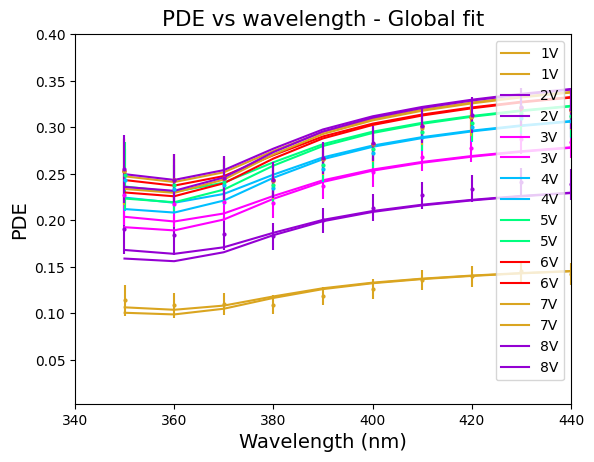

In [71]:
dict_final_global1 = {**resDict_global1, **fixedPars_global1}
print(dict_final_global1)
ms.ResetColorCycle()
for dc in data_global1:
    xwlen = dc["wlen"]
    theta = dc["theta1"]
    y = dc["yVals"]
    yErrs = dc["yErrs"]
    voltage = dc["voltage"]
    # if voltage != 6:
    #     continue
    # print(dc.keys())
    
    col = ms.GetNextColor()
    plt.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)
    
    # copyDict = dict_final_global1.copy()
    # copyDict["Vh"] = 13
    yFit = FF.PDE_allArgs_wlen_parametrized(wlen=xwlen, theta1=theta, voltage = voltage, **dict_final_global1)
    plt.plot(xwlen, yFit, color = col, label = f"{voltage}V")
    
    copyDict = {**dict_final_global1}
    copyDict["dp_star"] = 2
    yFit2 = FF.PDE_allArgs_wlen_parametrized(wlen=xwlen, theta1=theta, voltage = voltage, **copyDict)
    plt.plot(xwlen, yFit2, color = col, label = f"{voltage}V")
    

# plt.title("global fit")
fsize = 14
plt.xlim(340, 440)
plt.xlabel("Wavelength (nm)", fontsize = fsize)
plt.ylabel("PDE", fontsize = fsize)
plt.title("PDE vs wavelength - Global fit", fontsize = 1.1 * fsize)
plt.legend()
plt.show()

1, 0.475454, 0.00221301
2, 0.713112, 0.00242933
3, 0.838329, 0.0026546
4, 0.906976, 0.00280772
5, 0.95025, 0.00292199
6, 0.970392, 0.00299275
7, 0.984652, 0.00305944
8, 0.991921, 0.00311978
9, 0.995033, 0.003172


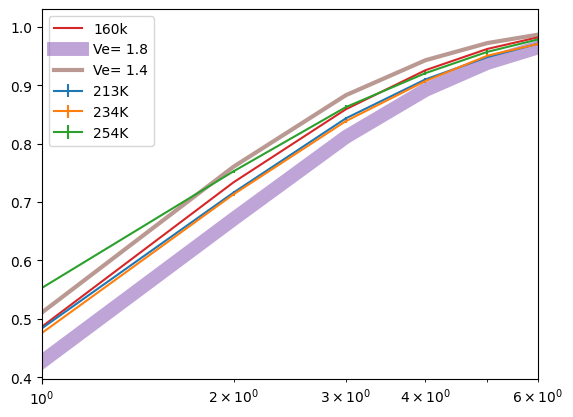

In [72]:
## more PE data from harry (different temps)
# Overvoltage values (in volts)

## 213K
overvoltage_213k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_213k = [0.483472, 0.716106, 0.843067, 0.909759, 0.947856, 0.970744, 0.986914, 0.991769, 0.995295]
pa_error_213k = [0.00141454, 0.00177954, 0.00201053, 0.00214232, 0.00222166, 0.00227794, 0.00232136, 0.002344, 0.00236474]
plt.errorbar(overvoltage_213k, pa_213k, pa_error_213k, label = "213K")

## 234K
overvoltage_234k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_234k = [0.475454, 0.713112, 0.838329, 0.906976, 0.95025, 0.970392, 0.984652, 0.991921, 0.995033]
pa_error_234k = [0.00221301, 0.00242933, 0.0026546, 0.00280772, 0.00292199, 0.00299275, 0.00305944, 0.00311978, 0.003172]
plt.errorbar(overvoltage_234k, pa_234k, pa_error_234k, label = "234K")

#printing 213 data transposed to copy into csv
for v, pe, errpe in zip(overvoltage_234k, pa_234k, pa_error_234k):
  print(f"{v}, {pe}, {errpe}")

## -20
overvoltage_254k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_254k = [0.552663, 0.752471, 0.862244, 0.920471, 0.956795, 0.978047, 0.986519, 0.993679, 0.997341]
pa_error_254k = [0.00249031, 0.00291201, 0.0032007, 0.00339486, 0.00355269, 0.00367885, 0.00378663, 0.00389088, 0.00399673]
plt.errorbar(overvoltage_254k, pa_254k, pa_error_254k, label = "254K")

plt.plot(harryVoltagePE, harryPe, label="160k")


plt.plot(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, Vc=1.8), linewidth = 10, alpha=0.6, label = f"Ve= {1.8}")

plt.plot(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, Vc=1.4), linewidth = 3, alpha=0.6, label = f"Ve= {1.4}")

plt.xlim(1, 6)
plt.xscale("log")
# plt.ylim(0.9, 1)
plt.legend()
plt.show()

Vc = 1.205 ± 2.078
vs = 0.292 ± 1.132


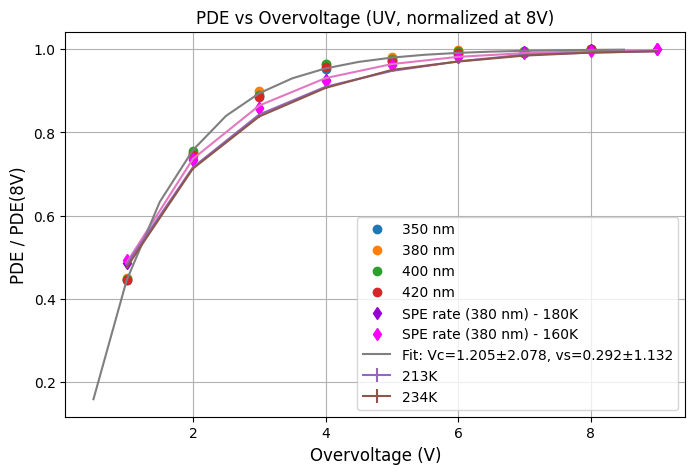

In [152]:
# plot PDE vs overvoltage, for different wlens, normalized by 8V value
target_wlens = [350, 380, 400, 420]
buffer = 1  # nm

pde380_toFit = []
pdeV_380 = []
plt.figure(figsize=(8, 5))
for wl_target in target_wlens:
    # Find wavelengths within buffer of target
    df_wl = df[(df['Wavelength'] >= wl_target - buffer) & (df['Wavelength'] <= wl_target + buffer) & (df['Angle'] == 0)]
    if len(df_wl) == 0:
        print(f"No data for {wl_target}nm")
        continue
    # Get unique voltages and average PDE per voltage
    grouped = df_wl.groupby('Overvoltage')['PDE'].mean()
    voltages = grouped.index.values
    pde_vals = grouped.values
    
    # Normalize by 8V value (or closest to 8V)
    idx_8v = np.argmin(np.abs(voltages - 8))
    pde_norm = pde_vals / pde_vals[idx_8v]

    if wl_target == 380:
        pde380_toFit = pde_norm
        pdeV_380 = voltages
    
    actual_wl = df_wl['Wavelength'].mean()
    plt.plot(voltages, pde_norm, 'o', label=f'{actual_wl:.0f} nm')

plt.plot(harryVoltagePE, harryPe, linestyle =  "None",marker = 'd', color = ms.lxe.col, label="SPE rate (380 nm) - 180K")  # plot PE data normalized by its 8V value
plt.errorbar(overvoltage_213k, pa_213k, pa_error_213k, label = "213K")
plt.errorbar(overvoltage_234k, pa_234k, pa_error_234k, label = "234K")

## 160 QY paper
pe160V, pe160 = np.loadtxt(os.path.join(VERA_DATA_PATH, "PE_vsV", "VUV4_160K_380nm_QYpaper.csv"), delimiter=",", unpack=True)
plt.plot(pe160V, pe160, linestyle = "None", marker = 'd', color = ms.lxe2.col, label="SPE rate (380 nm) - 160K")  # plot PE data normalized by its 8V value

plt.plot(harryVoltagePE, ME.Pcar_parametrized(V = harryVoltagePE, Vc = 1.5, A = 1.0))

vs = -0.5
lowXs = np.arange(0.5, 9, 0.5)
# plt.plot(lowXs-vs, ME.Pcar_parametrized(V = lowXs-vs, Vc = 1.7, A = 1.0))

chisq = lambda Vc, vs: np.sum(((ME.Pcar_parametrized(pdeV_380-vs, Vc, 1.0) - pde380_toFit))**2)
m = Minuit(chisq, Vc=1.5, vs = 0.1);
m.limits["Vc"] = (0.5, 3)
m.limits["vs"] = (-1, 1)

m.migrad()
print(f"Vc = {m.values['Vc']:.3f} ± {m.errors['Vc']:.3f}")
print(f"vs = {m.values['vs']:.3f} ± {m.errors['vs']:.3f}")

plt.plot(lowXs, ME.Pcar_parametrized(lowXs-m.values['vs'], m.values['Vc'], 1.0), label = f"Fit: Vc={m.values['Vc']:.3f}±{m.errors['Vc']:.3f}, vs={m.values['vs']:.3f}±{m.errors['vs']:.3f}")

# plt.plot(lowXs-m.values['vs'], ME.Pcar_parametrized(lowXs, m.values['Vc'], 1.0), label = f"Fit: Vc={m.values['Vc']:.3f}±{m.errors['Vc']:.3f}, vs={m.values['vs']:.3f}±{m.errors['vs']:.3f}")
# plt.plot(lowXs+0.2, ME.Pcar_parametrized(V = lowXs, Vc = 1.2, A = 1.0), label = "test")
# plt.plot(lowXs, ME.Pcar_parametrized(V = lowXs, Vc = 1.2, A = 1.0), label = "test")
# plt.plot(lowXs-0.2, ME.Pcar_parametrized(V = lowXs, Vc = 1.2, A = 1.0), label = "test")
# plt.plot(lowXs, ME.Pcar_parametrized(V = lowXs+0.2, Vc = 1.2, A = 1.0), label = "test")


plt.xlabel("Overvoltage (V)", fontsize=12)
plt.ylabel("PDE / PDE(8V)", fontsize=12)
plt.title("PDE vs Overvoltage (UV, normalized at 8V)")
plt.legend()
plt.grid()
plt.show()

[-0.06530873 -0.06891716 -0.05267628 -0.03787265 -0.02691833 -0.01937364
 -0.01488046 -0.00973421]


[]

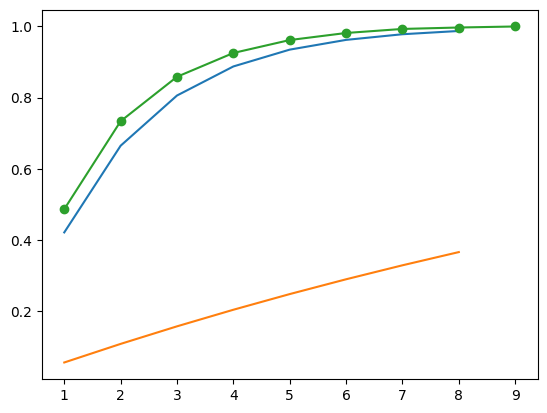

In [74]:
fitPeVals = ME.Pcar_parametrized(data_voltages, Vc=1.83)
plt.plot(data_voltages, fitPeVals)
plt.plot(data_voltages, ME.Pcar_parametrized(data_voltages, Vc=resDict_global1["Vh"], A=1.0), label = "Ph")

plt.plot(harryVoltagePE, harryPe, marker = "o")

print(fitPeVals - harryPe[:-1])
plt.plot()

In [75]:
import json

# Combine the dictionaries
combined_dict = {key: [resDict_global1[key], resDictErrors_global1[key]] for key in resDict_global1}

# Convert the combined dictionary to JSON with compact arrays
json_table = json.dumps(combined_dict, indent=None, separators=(',', ': '), sort_keys=False)

# Manually format the JSON string to add a newline after each key-value pair
formatted_json_table = json_table.replace('],', '],\n')
# formatted_json_table = json_table.replace('{', '{\n')
# formatted_json_table = json_table.replace('}', '}\n')

# Print the formatted JSON table
print(formatted_json_table)

{"dp_star": [1.3892,0.2398],
"Xpn": [2388.2901,68.6929],
"dw_star": [14133.0629,805.0354],
"Ve": [1.8285,0.0225],
"Vh": [17.5744,1.2662]}


---
## Non-parametrized Pe, Ph (nested float) - UV only

* float global: $dp^*$, $X_{pn}$, $dw^*$
* nested float: $P_e$, $P_h$

next try floatin Xpn for each voltage

In [76]:
##-- Buiding Vis all dataset --##
print(data_voltages[:])
data_global_nested_UV = []

for V in data_voltages[:]:
    df_nested = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A) & (df['Wavelength'] < 390)]
    fullError = quadErrors(df_nested['PDE'].values, df_nested['PDE_error'].values, sys1.diodeError, getClosestNCAError(V))
    oneD_dict = {"wlen":df_nested['Wavelength'].values, "yVals": df_nested['PDE'].values, "yErrs": fullError, "theta1": angle_0A, "ph":0.0}
    
    ## global dataset, float pe, ph
    fullFloat = {"pe": ME.Pcar_parametrized(V, Vc=resDict_global1["Ve"]),
                #  "ph": ME.Pcar_parametrized(V, Vc=resDict_global1["Vh"])}
                }
    # print(ME.Pcar_parametrized(V, Vc=resDict_global1["Vh"]))
    fullBounds = {"pe": (0.0, 1.1)}
    
    odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat.copy(), nuisanceBounds=fullBounds,
                                    nuisanceFixed={})
    odFull_global.extraV = V
    data_global_nested_UV.append(odFull_global)

[1 2 3 4 5 6 7 8]


In [77]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen))

fixedPars_global_nested_UV = {**fixedPars_physics, **fixedPars_Boring, "Xpn": 2.4e3, "dw_star": 6e3}
print("fixed inputs:", fixedPars_global_nested_UV)
print("\nfixed inputs:", fixedPars_global_nested_UV)

floatPars_global_nested_UV = {"dp_star":1.2}
floatParBounds_global_nested_UV = {"dp_star":(0.01, 15)}

x0_global_nested_UV, x0_global_nested_UV_Names = SS.BuildX0(floatDict=floatPars_global_nested_UV, functionToFit=FF.PDE_allArgs_wlen)
x0_global_nested_UV_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global_nested_UV, functionToFit=FF.PDE_allArgs_wlen)

print("------ Case global_nested_UV setup ------")

# dd = data_global_nested_UV[0].oneDData[0]
# print(data_global_nested_UV[0].mDict_nuisFloat)
# FF.PDE_allArgs_wlen(wlen=dd["wlen"], theta1=dd["theta1"], **fixedPars_global_nested_UV, **floatPars_global_nested_UV, **data_global_nested_UV[0].mDict_nuisFloat)
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_nested_UV, globalFixed=fixedPars_global_nested_UV, dataPackage=data_global_nested_UV,
                               functionToFit=FF.PDE_allArgs_wlen, verbose=False)

# for oneD in data_global_nested_UV:
#     print(oneD.extraV)
#     print(oneD.mDict_nuisFloat)
#     plt.plot(oneD.oneDData[0]["wlen"], oneD.oneDData[0]["yVals"], label = f"{oneD.extraV}V", marker = "o", color="red", linestyle = "")
#     print(len(oneD.oneDData[0]["wlen"]))
#     # print(oneD.nuisanceBounds)
#     print(oneD.resultDict.values())

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
fixed inputs: {'tOxide': 19.51, 'case': 'B', 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True, 'Xpn': 2400.0, 'dw_star': 6000.0}

fixed inputs: {'tOxide': 19.51, 'case': 'B', 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True, 'Xpn': 2400.0, 'dw_star': 6000.0}
------ Case global_nested_UV setup ------


(11.828645325006045+0j)

In [78]:
starTime = time.time()
globalFit_global_nested_UV = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_nested_UV, bounds = x0_global_nested_UV_bounds,
                                        args=(fixedPars_global_nested_UV, data_global_nested_UV, FF.PDE_allArgs_wlen), method='migrad')

SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_global_nested_UV.x, globalFixed=fixedPars_global_nested_UV, dataPackage=data_global_nested_UV,
                                    functionToFit=FF.PDE_allArgs_wlen, verbose=False)
print("Done fit!, time taken:", time.time()-starTime)

Done fit!, time taken: 5.064723968505859


In [79]:
# print(globalFit_Visall_S)
print("score:", globalFit_global_nested_UV.fun)
resDict_global_nested_UV = SS.GetResDict(globalFit_global_nested_UV, x0_global_nested_UV_Names)
resDictError_global_nested_UV = SS.GetResErrorDict(globalFit_global_nested_UV, x0_global_nested_UV_Names)
print(resDict_global_nested_UV)
print(resDictError_global_nested_UV)

peFull_dict_global_nested_UV = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_global_nested_UV}

print("pe:", peFull_dict_global_nested_UV)

score: 2.2025981235073244
{'dp_star': 0.01}
{'dp_star': 0.0}
pe: {1: (0.3883, 0.0128), 2: (0.6527, 0.0185), 3: (0.7739, 0.0204), 4: (0.8334, 0.021), 5: (0.8489, 0.025), 6: (0.8669, 0.0226), 7: (0.8659, 0.0246), 8: (0.8688, 0.0244)}


{'dp_star': 0.01, 'tOxide': 19.51, 'case': 'B', 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True, 'Xpn': 2400.0, 'dw_star': 6000.0}


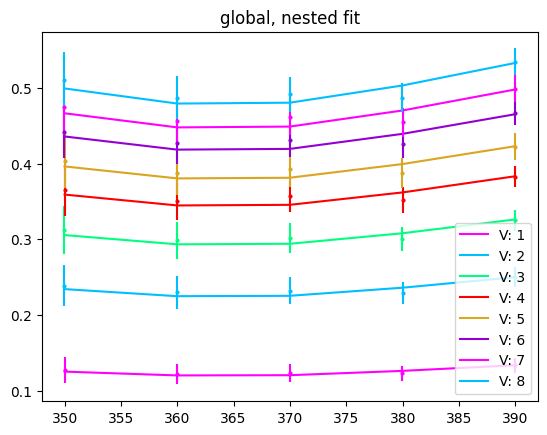

In [80]:
dict_final_global_nested_UV = {**resDict_global_nested_UV, **fixedPars_global_nested_UV}
print(dict_final_global_nested_UV)

for dc in data_global_nested_UV:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localScaling = 1 + 1*voltage / 8
    localPe = peFull_dict_global_nested_UV[voltage][0]
    pArgs = dc.resultDict
    
    col = ms.GetNextColor()
    yFit = localScaling * FF.PDE_allArgs_wlen(wlen=xwlen, theta1=oneD["theta1"], ph = oneD["ph"], **dict_final_global_nested_UV, **pArgs)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    
    # copyDict = dict_final_global_nested_UV.copy()
    # copyDict["dp_star"] = 0.3
    # yFit_short = localScaling* FF.PDE_allArgs_wlen(wlen=xwlen, theta1=oneD["theta1"], **copyDict, **pArgs)
    # plt.plot(xwlen, yFit_short, color = col, linestyle = "--")
    
    plt.errorbar(xwlen, localScaling*y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)

# plt.xlim(340, 450)
plt.title("global, nested fit")
plt.legend()
plt.show()

---
## Non-parametrized Pe, Ph - IR only

* float global: $dp^*$, $X_{pn}$, $dw^*$
* nested float: $P_e$, $P_h$

next try floatin Xpn for each voltage

In [81]:
##-- Buiding Vis all dataset --##
print(data_voltages[:])
data_global_nested_IR = []

for V in data_voltages[:]:
    df_nested = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
    fullError = quadErrors(df_nested['PDE'].values, df_nested['PDE_error'].values, sys1.diodeError, getClosestNCAError(V))
    pe_toUse = peFull_dict_global_nested_UV[V][0]
    oneD_dict = {"wlen":df_nested['Wavelength'].values, "yVals": df_nested['PDE'].values, "yErrs": fullError, "theta1": angle_0A, "pe":pe_toUse}
    
    ## global dataset, float pe, ph
    fullFloat = {"ph": ME.Pcar_parametrized(V, Vc=resDict_global1["Vh"])
                }
    # print(ME.Pcar_parametrized(V, Vc=resDict_global1["Vh"]))
    fullBounds = {"ph": (0.0, 1.1)}
    
    odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat.copy(), nuisanceBounds=fullBounds,
                                    nuisanceFixed={})
    odFull_global.extraV = V
    data_global_nested_IR.append(odFull_global)

[1 2 3 4 5 6 7 8]


In [82]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen))

fixedPars_global_nested_IR = {**fixedPars_physics, **fixedPars_Boring, **resDict_global_nested_UV}
print("fixed inputs:", fixedPars_global_nested_IR)
print("\nfixed inputs:", fixedPars_global_nested_IR)

floatPars_global_nested_IR = {"Xpn": 2.4e3, "dw_star": 6e3}
floatParBounds_global_nested_IR = {"Xpn": (1.0e3, 4.0e3), "dw_star": (4e3, 20e3)}

x0_global_nested_IR, x0_global_nested_IR_Names = SS.BuildX0(floatDict=floatPars_global_nested_IR, functionToFit=FF.PDE_allArgs_wlen)
x0_global_nested_IR_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global_nested_IR, functionToFit=FF.PDE_allArgs_wlen)

print("------ Case global_nested_IR setup ------")

# dd = data_global_nested_IR[0].oneDData[0]
# print(data_global_nested_IR[0].mDict_nuisFloat)
# FF.PDE_allArgs_wlen(wlen=dd["wlen"], theta1=dd["theta1"], **fixedPars_global_nested_IR, **floatPars_global_nested_IR, **data_global_nested_IR[0].mDict_nuisFloat)
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_nested_IR, globalFixed=fixedPars_global_nested_IR, dataPackage=data_global_nested_IR,
                               functionToFit=FF.PDE_allArgs_wlen, verbose=False)

# for oneD in data_global_nested_IR:
#     print(oneD.extraV)
#     print(oneD.mDict_nuisFloat)
#     plt.plot(oneD.oneDData[0]["wlen"], oneD.oneDData[0]["yVals"], label = f"{oneD.extraV}V", marker = "o", color="red", linestyle = "")
#     print(len(oneD.oneDData[0]["wlen"]))
#     # print(oneD.nuisanceBounds)
#     print(oneD.resultDict.values())

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
fixed inputs: {'tOxide': 19.51, 'case': 'B', 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True, 'dp_star': 0.01}

fixed inputs: {'tOxide': 19.51, 'case': 'B', 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True, 'dp_star': 0.01}
------ Case global_nested_IR setup ------


(489.0094626895271+0j)

In [83]:
starTime = time.time()
globalFit_global_nested_IR = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_nested_IR, bounds = x0_global_nested_IR_bounds,
                                        args=(fixedPars_global_nested_IR, data_global_nested_IR, FF.PDE_allArgs_wlen), method='migrad')

SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_global_nested_IR.x, globalFixed=fixedPars_global_nested_IR, dataPackage=data_global_nested_IR,
                                    functionToFit=FF.PDE_allArgs_wlen, verbose=False)
print("Done fit!, time taken:", time.time()-starTime)

Done fit!, time taken: 18.627238988876343


In [84]:
# print(globalFit_Visall_S)
print("score:", globalFit_global_nested_IR.fun)
resDict_global_nested_IR = SS.GetResDict(globalFit_global_nested_IR, x0_global_nested_IR_Names)
resDictError_global_nested_IR = SS.GetResErrorDict(globalFit_global_nested_IR, x0_global_nested_IR_Names)
print(resDict_global_nested_IR)
print(resDictError_global_nested_IR)

peFull_dict_global_nested_IR = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global_nested_IR}

print("ph:", peFull_dict_global_nested_IR)

score: 351.87473316753915
{'Xpn': 2684.1844, 'dw_star': 11534.2017}
{'Xpn': 76.1717, 'dw_star': 645.3144}
ph: {1: (0.0476, 0.0032), 2: (0.1166, 0.0045), 3: (0.1893, 0.0051), 4: (0.2512, 0.0053), 5: (0.302, 0.0078), 6: (0.3521, 0.0066), 7: (0.3957, 0.0082), 8: (0.4344, 0.0084)}


{'Xpn': 2684.1844, 'dw_star': 11534.2017, 'tOxide': 19.51, 'case': 'B', 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True, 'dp_star': 0.01}


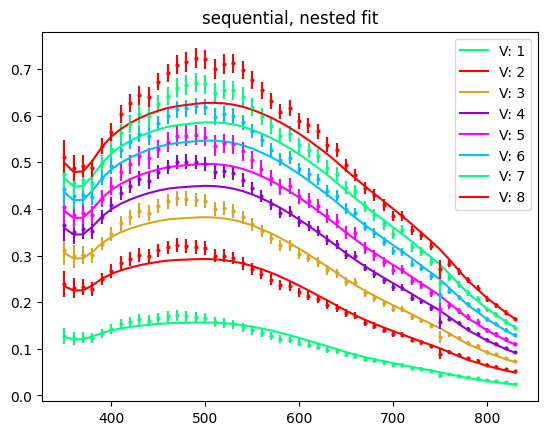

In [85]:
dict_final_global_nested_IR = {**resDict_global_nested_IR, **fixedPars_global_nested_IR}
print(dict_final_global_nested_IR)

for dc in data_global_nested_IR:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localScaling = 1 + 1*voltage / 8
    localPe = peFull_dict_global_nested_IR[voltage][0]
    pArgs = dc.resultDict
    
    col = ms.GetNextColor()
    yFit = localScaling * FF.PDE_allArgs_wlen(wlen=xwlen, theta1=oneD["theta1"], pe = oneD["pe"], **dict_final_global_nested_IR, **pArgs)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    
    # copyDict = dict_final_global_nested_IR.copy()
    # copyDict["dp_star"] = 0.3
    # yFit_short = localScaling* FF.PDE_allArgs_wlen(wlen=xwlen, theta1=oneD["theta1"], **copyDict, **pArgs)
    # plt.plot(xwlen, yFit_short, color = col, linestyle = "--")
    
    plt.errorbar(xwlen, localScaling*y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)

# plt.xlim(340, 450)
plt.title("sequential, nested fit")
plt.legend()
plt.show()

---
## Non-parametrized Pe, Ph (nested float)

* float global: $dp^*$, $X_{pn}$, $dw^*$
* nested float: $P_e$, $P_h$

next try floatin Xpn for each voltage

In [86]:
##-- Buiding Vis all dataset --##
print(data_voltages[:])
data_global_nested = []

for V in data_voltages[:]:
    df_nested = df[(df['Overvoltage'] == V) & (df['Angle'] == angle_0A)]
    fullError = quadErrors(df_nested['PDE'].values, df_nested['PDE_error'].values, sys1.diodeError, getClosestNCAError(V))
    oneD_dict = {"wlen":df_nested['Wavelength'].values, "yVals": df_nested['PDE'].values, "yErrs": fullError, "theta1": angle_0A}
    
    ## global dataset, float pe, ph
    fullFloat = {"pe": ME.Pcar_parametrized(V, Vc=resDict_global1["Ve"]),
                #  "ph": ME.Pcar_parametrized(V, Vc=resDict_global1["Vh"])}
                "ph": 0.4}
    print(ME.Pcar_parametrized(V, Vc=resDict_global1["Vh"]))
    fullBounds = {"pe": (0.0, 1.1), "ph": (0.0, 1.1)}
    
    odFull_global = SS.OneNuisanceDataSet(oneDData=oneD_dict, nuisanceFloat=fullFloat.copy(), nuisanceBounds=fullBounds,
                                    nuisanceFixed={})
    odFull_global.extraV = V
    data_global_nested.append(odFull_global)

[1 2 3 4 5 6 7 8]
0.05531236096409109
0.10756526465276028
0.15692793687118
0.2035602431457023
0.24761320646298024
0.2892294963717149
0.32854389103103143
0.36568371370186714


In [87]:
# global fixed
print("List of args needed:", SS.GetNames(FF.PDE_allArgs_wlen))

fixedPars_global_nested = {**fixedPars_physics, **fixedPars_Boring}
print("fixed inputs:", fixedPars_global_nested)
print("\nfixed inputs:", fixedPars_global_nested)

floatPars_global_nested = {"dp_star":1.2, "Xpn": 1e3, "dw_star": 6e3}
floatParBounds_global_nested = {"dp_star":(0.01, 15), "Xpn": (0.2e3, 4.5e3), "dw_star": (4.5e3, 15e3)}

x0_global_nested, x0_global_nested_Names = SS.BuildX0(floatDict=floatPars_global_nested, functionToFit=FF.PDE_allArgs_wlen)
x0_global_nested_bounds = SS.BuildX0_bounds(floatBoundsDict=floatParBounds_global_nested, functionToFit=FF.PDE_allArgs_wlen)

print("------ Case global_nested setup ------")

# dd = data_global_nested[0].oneDData[0]
# print(data_global_nested[0].mDict_nuisFloat)
# FF.PDE_allArgs_wlen(wlen=dd["wlen"], theta1=dd["theta1"], **fixedPars_global_nested, **floatPars_global_nested, **data_global_nested[0].mDict_nuisFloat)
SS.GenericResiduals_Nuisance_1(globalFloat=x0_global_nested, globalFixed=fixedPars_global_nested, dataPackage=data_global_nested,
                               functionToFit=FF.PDE_allArgs_wlen, verbose=False)

# for oneD in data_global_nested:
#     print(oneD.extraV)
#     print(oneD.mDict_nuisFloat)
#     plt.plot(oneD.oneDData[0]["wlen"], oneD.oneDData[0]["yVals"], label = f"{oneD.extraV}V", marker = "o", color="red", linestyle = "")
#     print(len(oneD.oneDData[0]["wlen"]))
#     # print(oneD.nuisanceBounds)
#     print(oneD.resultDict.values())

List of args needed: ['wlen', 'theta1', 'FF', 'tOxide', 'dp_star', 'Xpn', 'dw_star', 'pe', 'ph', 'Temperature', 'smoothSigma', 'quantum', 'dh', 'window', 'case']
fixed inputs: {'tOxide': 19.51, 'case': 'B', 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True}

fixed inputs: {'tOxide': 19.51, 'case': 'B', 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True}
------ Case global_nested setup ------


(302.0897422425558+0j)

In [88]:
starTime = time.time()
globalFit_global_nested = iminuit.minimize(SS.GenericResiduals_Nuisance_1, x0=x0_global_nested, bounds = x0_global_nested_bounds,
                                        args=(fixedPars_global_nested, data_global_nested, FF.PDE_allArgs_wlen), method='migrad')

SS.GenericResiduals_Nuisance_1(globalFloat=globalFit_global_nested.x, globalFixed=fixedPars_global_nested, dataPackage=data_global_nested,
                                    functionToFit=FF.PDE_allArgs_wlen, verbose=False)
print("Done fit!, time taken:", time.time()-starTime)

Done fit!, time taken: 57.25877785682678


In [89]:
# print(globalFit_Visall_S)
print("score:", globalFit_global_nested.fun)
resDict_global_nested = SS.GetResDict(globalFit_global_nested, x0_global_nested_Names)
resDictError_global_nested = SS.GetResErrorDict(globalFit_global_nested, x0_global_nested_Names)
print(resDict_global_nested)
print(resDictError_global_nested)

phFull_dict_global_nested = {dc.extraV: (dc.resultDict["ph"], dc.resultErrorsDict["ph"]) for dc in data_global_nested}
peFull_dict_global_nested = {dc.extraV: (dc.resultDict["pe"], dc.resultErrorsDict["pe"]) for dc in data_global_nested}

print("pe:", peFull_dict_global_nested)
print("ph:", phFull_dict_global_nested)

score: 112.80228731817331
{'dp_star': 1.5152, 'Xpn': 2126.2839, 'dw_star': 12431.1448}
{'dp_star': 0.2579, 'Xpn': 77.0326, 'dw_star': 650.3129}
pe: {1: (0.4043, 0.0046), 2: (0.6909, 0.0062), 3: (0.8326, 0.0066), 4: (0.9099, 0.0067), 5: (0.9349, 0.0091), 6: (0.9632, 0.0076), 7: (0.9687, 0.009), 8: (0.9787, 0.0089)}
ph: {1: (0.0692, 0.0035), 2: (0.143, 0.0048), 3: (0.2075, 0.0053), 4: (0.2582, 0.0055), 5: (0.299, 0.0079), 6: (0.3389, 0.0067), 7: (0.3731, 0.0083), 8: (0.4032, 0.0084)}


In [90]:
yph_global_nested = [phFull_dict_global_nested[voltage][0] for voltage in data_voltages]
yphErr_global_nested = [phFull_dict_global_nested[voltage][1] for voltage in data_voltages]

ype_global_nested = [peFull_dict_global_nested[voltage][0] for voltage in data_voltages]
ypeErr_global_nested = [peFull_dict_global_nested[voltage][1] for voltage in data_voltages]

# Prepare the data to write
data_to_write = {
    "overvoltage": data_voltages,
    "pe": ype_global_nested,
    "errpe": ypeErr_global_nested,
    "ph": yph_global_nested,
    "errph": yphErr_global_nested
}

# Convert the data to a DataFrame
df_output = pd.DataFrame(data_to_write)

# Write the DataFrame to a CSV file
df_output.to_csv(peOutFileName, index=False)

print(f"Pe and Ph curves have been written to {peOutFileName}")

Pe and Ph curves have been written to HPK_Pcurves_franta_global_nested_temp.csv


{'dp_star': 1.5152, 'Xpn': 2126.2839, 'dw_star': 12431.1448, 'tOxide': 19.51, 'case': 'B', 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True}


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


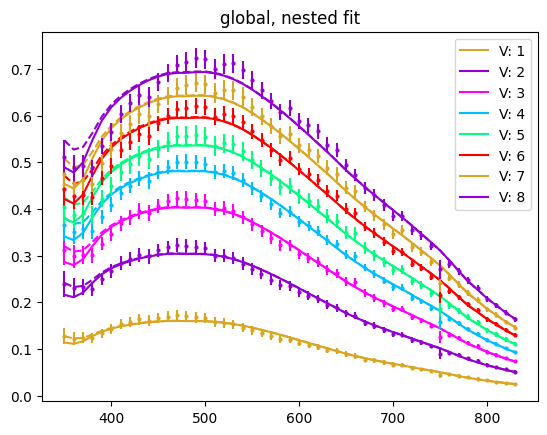

In [91]:
dict_final_global_nested = {**resDict_global_nested, **fixedPars_global_nested}
print(dict_final_global_nested)

for dc in data_global_nested:
    oneD = dc.oneDData[0]
    xwlen = oneD["wlen"]
    y = oneD["yVals"]
    yErrs = oneD["yErrs"]
    
    voltage = dc.extraV
    localScaling = 1 + 1*voltage / 8
    localPe = peFull_dict_global_nested[voltage][0]
    localPh = phFull_dict_global_nested[voltage][0]
    pArgs = {"pe": localPe, "ph": localPh}
    pArgs = dc.resultDict
    
    col = ms.GetNextColor()
    yFit = localScaling * FF.PDE_allArgs_wlen(wlen=xwlen, theta1=oneD["theta1"], **dict_final_global_nested, **pArgs)
    plt.plot(xwlen, yFit, color = col, label=f"V: {dc.extraV}")
    
    
    copyDict = dict_final_global_nested.copy()
    copyDict["dp_star"] = 0.3
    yFit_short = localScaling* FF.PDE_allArgs_wlen(wlen=xwlen, theta1=oneD["theta1"], **copyDict, **pArgs)
    plt.plot(xwlen, yFit_short, color = col, linestyle = "--")
    
    plt.errorbar(xwlen, localScaling*y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=2)

# plt.xlim(340, 450)
plt.title("global, nested fit")
plt.legend()
plt.show()

---
### Plotting all ATP curves

In [92]:
ms.ResetColorCycle()



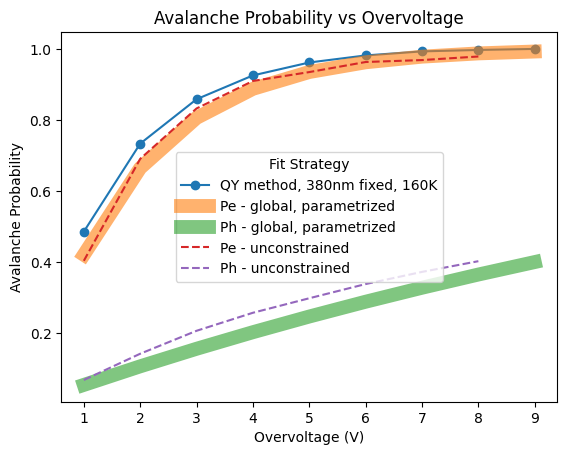

In [93]:

## more PE data from harry (different temps)
# Overvoltage values (in volts)

## 213K
overvoltage_213k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_213k = [0.483472, 0.716106, 0.843067, 0.909759, 0.947856, 0.970744, 0.986914, 0.991769, 0.995295]
pa_error_213k = [0.00141454, 0.00177954, 0.00201053, 0.00214232, 0.00222166, 0.00227794, 0.00232136, 0.002344, 0.00236474]

## 234K
overvoltage_234k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_234k = [0.475454, 0.713112, 0.838329, 0.906976, 0.95025, 0.970392, 0.984652, 0.991921, 0.995033]
pa_error_234k = [0.00221301, 0.00242933, 0.0026546, 0.00280772, 0.00292199, 0.00299275, 0.00305944, 0.00311978, 0.003172]

## -20
overvoltage_254k = [1, 2, 3, 4, 5, 6, 7, 8, 9]
pa_254k = [0.552663, 0.752471, 0.862244, 0.920471, 0.956795, 0.978047, 0.986519, 0.993679, 0.997341]
pa_error_254k = [0.00249031, 0.00291201, 0.0032007, 0.00339486, 0.00355269, 0.00367885, 0.00378663, 0.00389088, 0.00399673]

# other temps
# plt.errorbar(overvoltage_213k, pa_213k, pa_error_213k, marker = "o", label = "213K")
# plt.errorbar(overvoltage_234k, pa_234k, pa_error_234k, marker = "o", label = "234K")
# plt.errorbar(overvoltage_254k, pa_254k, pa_error_254k, marker = "o", label = "254K")

plt.plot(harryVoltagePE, harryPe, marker = "o", label="QY method, 380nm fixed, 160K")

plt.plot(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, Vc=resDict_global1["Ve"]), linewidth = 10, alpha=0.6, label = "Pe - global, parametrized")
plt.plot(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, Vc=resDict_global1["Vh"]), linewidth = 10, alpha=0.6, label = "Ph - global, parametrized")

plt.plot(data_voltages, ype_global_nested, linestyle = "--", label = "Pe - unconstrained")
plt.plot(data_voltages, yph_global_nested, linestyle = "--", label = "Ph - unconstrained")

# plt.xscale("log")

plt.ylabel("Avalanche Probability")
plt.xlabel("Overvoltage (V)")
plt.title("Avalanche Probability vs Overvoltage")
# plt.xlim(4, 8)
# plt.ylim(0.9, 1)

plt.legend(title = "Fit Strategy")
plt.show()

---
### Summarizing the fits


In [94]:
print("fit options:",   fitFlag)
print("UV high V:",     resDict_A_UV, result_A_UV.fun)
print("UV all:",        resDict_UV, result_UV.fun)
print("IR :",           resDict_ir, result_ir.fun)
print("global, par:", resDict_global1, result_global1.fun)
print("global, free P", resDict_global_nested, globalFit_global_nested.fun)
print("pe:", ype_global_nested[-1])

fit options: 
UV high V: {'dp_star': 2.144} 3.3579022165320938
UV all: {'dp_star': 1.1297, 'Ve': 1.6813} 9.545720206795709
IR : {'Xpn': 2038.4343, 'dw_star': 11899.1739, 'Vh': 13.3651} 219.63925860706203
global, par: {'dp_star': 1.3892, 'Xpn': 2388.2901, 'dw_star': 14133.0629, 'Ve': 1.8285, 'Vh': 17.5744} 191.33755127302354
global, free P {'dp_star': 1.5152, 'Xpn': 2126.2839, 'dw_star': 12431.1448} 112.80228731817331
pe: 0.9787


---
## Showing all final fits

A - parameterized, sequential  
B - parameterized, global  
C - nested, sequential  
D - nested, global  

we want to compare A, D for Franta, oxide uncertainties.


In [95]:
## hard coded final results for Franta

# B is global parametrized fit
setB_Franta = {"dp_star": 0.82, "Xpn": 2675, "dw_star": 5850, "Ve": 1.83, "Vh": 4.68}
setB_Franta_errors = {"dp_star": 0.21, "Xpn": 134, "dw_star": 98, "Ve": 0.02, "Vh": 0.33}

# setD_franta = {"dp_star": 1.2, "Xpn": 2.4e3, "dw_star": 6e3, "Ve": 1.5, "Vh": 18}
# setD_franta_errors = {"dp_star": 0.1, "Xpn": 0.2e3, "dw_star": 1e3, "Ve": 0.1, "Vh": 2}

{'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True, 'tOxide': 19.51, 'case': 'B', 'Ae': 1.0, 'Ah': 1.0}
Franta's set B: {'dp_star': 0.82, 'Xpn': 2675, 'dw_star': 5850, 'Ve': 1.83, 'Vh': 4.68, 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': None, 'dh': <PDEModel.OpticsDataLoader.OpticsData object at 0x17e3e1350>, 'quantum': True, 'window': True, 'tOxide': 19.51, 'case': 'B', 'Ae': 1.0, 'Ah': 1.0}
{'dp_star': 1.3892, 'Xpn': 2388.2901, 'dw_star': 14133.0629, 'Ve': 1.8285, 'Vh': 17.5744, 'FF': 0.6, 'smoothSigma': 5.94, 'Temperature': 160, 'dh': None, 'quantum': True, 'window': True, 'tOxide': 19.51, 'case': 'B', 'Ae': 1.0, 'Ah': 1.0}


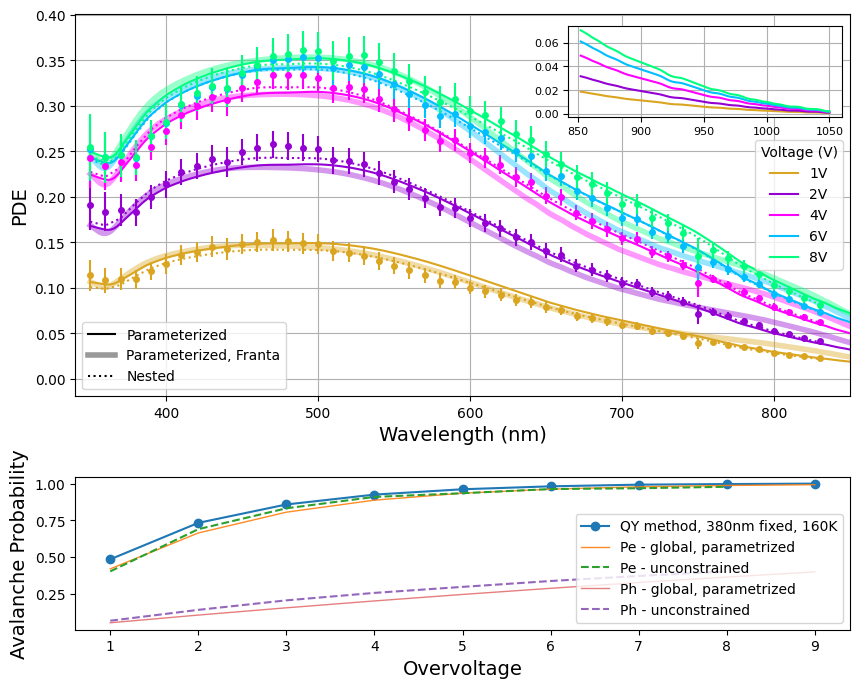

In [96]:
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

print(fixedPars_global1)

dict_final_setB = {**resDict_global1, **fixedPars_global1} ## global fit, nested
dict_final_setA = {**resDict_UV, **resDict_ir, **fixedPars_global1} ## sequential fit, parametrized

dict_final_setD = {**resDict_global_nested, **fixedPars_global_nested} ## global fit, nested

dict_final_setB_franta = {**setB_Franta, **fixedPars_global1} ## global fit, Franta
dict_final_setB_franta["tOxide"] = 19.51
dict_final_setB_franta["dh"] = dhFranta
dict_final_setB_franta["Temperature"] = None
print("Franta's set B:", dict_final_setB_franta)

print(dict_final_setB)
ms.ResetColorCycle()

ls_par_global = "-"
ls_nested = ":"
ls_par_seq = "--"
line_franta = {"linewidth":4, "alpha":0.4}

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), height_ratios=[2.5, 1])

spot = (660, 0.28, 180, 0.1) # (x0, y0, width, height) in axes coordinates
axins = inset_axes(ax1, width="100%", height="100%", loc="lower left", bbox_to_anchor=spot, bbox_transform=ax1.transData)

for i, dc in enumerate(data_global1):
    xwlen = dc["wlen"]
    theta = dc["theta1"]
    y = dc["yVals"]
    yErrs = dc["yErrs"]
    voltage = dc["voltage"]
    
    if voltage == 3 or voltage == 5 or voltage == 7:
        continue
    
    col = ms.GetNextColor()
    ax1.errorbar(xwlen, y, yerr=yErrs, color = col, linestyle = "", marker="o", markersize=4)
    
    xFit = np.arange(min(xwlen), 1050, 2)
    # copyDict = dict_final_setB.copy()
    # copyDict["Vh"] = 13
    yFit_seq_par = FF.PDE_allArgs_wlen_parametrized(wlen=xwlen, theta1=theta, voltage = voltage, **dict_final_setA)
    # ax1.plot(xwlen, yFit_seq_par, color = col, linestyle = ls_par_seq)
    
    yFit_g_par_B = FF.PDE_allArgs_wlen_parametrized(wlen=xFit, theta1=theta, voltage = voltage, **dict_final_setB)
    ax1.plot(xFit, yFit_g_par_B, color = col, linestyle = ls_par_global, label = f"{voltage}V")
    
    thisPe_setD = peFull_dict_global_nested[voltage][0]
    thisPh_setD = phFull_dict_global_nested[voltage][0]
    yFit_g_nested = FF.PDE_allArgs_wlen(wlen=xwlen, theta1=theta, **dict_final_global_nested, pe=thisPe_setD, ph=thisPh_setD)
    ax1.plot(xwlen, yFit_g_nested, color = col, linestyle = ls_nested)
    
    yFit_g_par_B_franta = FF.PDE_allArgs_wlen_parametrized(wlen=xFit, theta1=theta, **dict_final_setB_franta, voltage = voltage)
    ax1.plot(xFit, yFit_g_par_B_franta, color = col, linestyle = ls_par_global, **line_franta)

    upperLim = 850
    redMap = xFit > upperLim
    axins.plot(xFit[redMap], yFit_g_par_B[redMap], color = col, linestyle = ls_par_global)
    # axins.plot(xFit[redMap], yFit_g_par_B_franta[redMap], color = col, linestyle = ls_par_global, **line_franta)

# axins.set_xlim(850, 1050)

# Add the normal legend
leg1 = ax1.legend(title="Voltage (V)", loc="center right")

# Create dummy artists for the second legend (line styles)
dummy_lines = [
    Line2D([0], [0], color="black", linestyle=ls_par_global, label="Parameterized"),
    Line2D([0], [0], color="black", **line_franta,  label="Parameterized, Franta"),
    # Line2D([0], [0], color="black", linestyle=ls_par_seq, label="Sequential Parameterized"),
    Line2D([0], [0], color="black", linestyle=ls_nested, label="Nested"),
]

# Add the second legend (for line styles)
leg2 = ax1.legend(handles=dummy_lines, loc="lower left")
# ax1.set_ylim(-0.05, ax1.get_ylim()[1])  # Adjust x-limits to match inset

axins.tick_params(labelsize=8)
axins.grid()

ax1.add_artist(leg1)  # Add the first legend back to the plot
# ax1.xaxis.set_ticks()

fsize = 14
ax1.set_ylabel("PDE", fontsize=fsize)
ax1.set_xlabel("Wavelength (nm)", fontsize=fsize)

ax1.set_xlim(min(xwlen)-10, 850)
ax1.grid()

# ax1.set_title("PDE vs wavelength - Global fit", fontsize=1.1 * fsize)

ax2.plot(harryVoltagePE, harryPe, marker = "o", label="QY method, 380nm fixed, 160K")

## first Pe curve
ax2.plot(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, Vc=resDict_global1["Ve"]), linewidth = 1, alpha=0.9, label = "Pe - global, parametrized")
# pe1_low = ME.Pcar_parametrized(harryVoltagePE+10*sys1.vOffset, Vc=resDict_global1["Ve"] + resDictErrors_global1["Ve"])
# pe1_high = ME.Pcar_parametrized(harryVoltagePE-sys1.vOffset, Vc=resDict_global1["Ve"] - resDictErrors_global1["Ve"])
# ax2.fill_between(harryVoltagePE, pe1_low, pe1_high, alpha=0.1, color="red")

ax2.plot(data_voltages, ype_global_nested, linestyle = "--", label = "Pe - unconstrained")

# ax2.fill_between(harryVoltagePE, 0, ME.Pcar_parametrized(harryVoltagePE, Vc=resDict_global1["Ve"]), alpha=0.1, color="blue")

ax2.plot(harryVoltagePE, ME.Pcar_parametrized(harryVoltagePE, Vc=resDict_global1["Vh"]), linewidth = 1, alpha=0.6, label = "Ph - global, parametrized")

ax2.plot(data_voltages, yph_global_nested, linestyle = "--", label = "Ph - unconstrained")

ax2.set_xlabel("Overvoltage", fontsize=fsize)
ax2.set_ylabel("Avalanche Probability", fontsize=fsize)

ax2.legend()

plt.subplots_adjust(hspace=0.3)
plt.show()